# Voice Recording Preprocessing

This notebook prepares the group's voice recordings for the voice-identification part of the assignment. The recordings are checked, their waveforms and spectrograms are examined, augmented versions are created, and audio features are extracted for the models.

## Recordings used

Each participant recorded two phrases:

- “Yes, approve”
- “Confirm transaction”

The WAV files are organised by participant and phrase inside `data/audio/raw/`. The folder names or filenames are used to identify the speaker and phrase. Recordings are not created by the notebook, and missing labels are not guessed.

Example folder layout:

```text
data/audio/raw/
  Ella/yes_approve/
  Ella/confirm_transaction/
  King/yes_approve/
  King/confirm_transaction/
  Nicole/yes_approve/
  Nicole/confirm_transaction/
  Sarah/yes_approve/
  Sarah/confirm_transaction/
```

## 1. Imports and project paths

The libraries needed to read and process WAV files, display plots and extract features are imported. The recordings are converted to mono and resampled to 16 kHz so that feature extraction uses the same audio format for every participant.

In [1]:
import sys
import re
from pathlib import Path
from math import gcd

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import resample_poly, stft, istft
from scipy.fft import dct
from tqdm.auto import tqdm

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "audio" / "raw"
PROCESSED_DIR = ROOT / "data" / "audio" / "processed"
AUGMENTED_DIR = PROCESSED_DIR / "augmented"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
AUGMENTED_DIR.mkdir(parents=True, exist_ok=True)

TARGET_SR = 16000
PARTICIPANTS = {
    "ella": "participant_01", "participant_01": "participant_01",
    "king": "participant_02", "participant_02": "participant_02",
    "nicole": "participant_03", "participant_03": "participant_03",
    "sarah": "participant_04", "participant_04": "participant_04",
}
PHRASES = {
    "yes_approve": ["yes_approve", "yes approve", "approve"],
    "confirm_transaction": ["confirm_transaction", "confirm transaction", "confirm"],
}
AUDIO_EXTENSIONS = {".wav"}

print("Project root:", ROOT)
print("Raw audio folder:", RAW_DIR)
print("Raw folder exists:", RAW_DIR.exists())

Python: 3.14.6
NumPy: 2.5.1
Pandas: 3.0.3
Project root: c:\Users\a\Documents\formative_2_data_processing_personal
Raw audio folder: c:\Users\a\Documents\formative_2_data_processing_personal\data\audio\raw
Raw folder exists: True


## 2. Find the recordings and identify their labels

The audio folders and filenames are searched to identify the participant and phrase for each recording. Any file with an unclear speaker or phrase label is reported instead of being assigned a label without evidence.

In [2]:
def path_tokens(path):
    rel = path.relative_to(RAW_DIR)
    return [part.lower().replace("-", "_").replace(" ", "_") for part in rel.parts[:-1]] + [
        path.stem.lower().replace("-", "_").replace(" ", "_")
    ]

def identify_participant(path):
    joined = "_".join(path_tokens(path))
    for alias, label in PARTICIPANTS.items():
        if re.search(rf"(?<![a-z0-9]){re.escape(alias)}(?![a-z0-9])", joined):
            return label
    return None

def identify_phrase(path):
    joined = "_".join(path_tokens(path))
    matches = []
    for phrase, aliases in PHRASES.items():
        if any(re.search(rf"(?<![a-z0-9]){re.escape(alias.replace(' ', '_'))}(?![a-z0-9])", joined)
               for alias in aliases):
            matches.append(phrase)
    return matches[0] if len(matches) == 1 else None

if not RAW_DIR.exists():
    raise FileNotFoundError(
        f"Audio folder not found: {RAW_DIR}\n"
        "Create data/audio/raw/ and place the real participant WAV recordings inside it."
    )

audio_paths = sorted(p for p in RAW_DIR.rglob("*")
                     if p.is_file() and p.suffix.lower() in AUDIO_EXTENSIONS)
records, unresolved = [], []
for path in audio_paths:
    participant = identify_participant(path)
    phrase = identify_phrase(path)
    if participant is None or phrase is None:
        unresolved.append({
            "file": str(path.relative_to(RAW_DIR)),
            "participant_detected": participant,
            "phrase_detected": phrase
        })
    else:
        records.append({"path": path, "participant_id": participant, "phrase": phrase})

inventory = pd.DataFrame(records)
print("WAV files found:", len(audio_paths))
print("Recordings with recognized labels:", len(inventory))
print("Unresolved files:", len(unresolved))
display(inventory.head(20))
if unresolved:
    display(pd.DataFrame(unresolved))

WAV files found: 8
Recordings with recognized labels: 8
Unresolved files: 0


,path,participant_id,phrase
0,c:\Users\a\Documents\formative_2_data_processi...,participant_01,confirm_transaction
1,c:\Users\a\Documents\formative_2_data_processi...,participant_01,yes_approve
2,c:\Users\a\Documents\formative_2_data_processi...,participant_02,confirm_transaction
3,c:\Users\a\Documents\formative_2_data_processi...,participant_02,yes_approve
4,c:\Users\a\Documents\formative_2_data_processi...,participant_03,confirm_transaction
5,c:\Users\a\Documents\formative_2_data_processi...,participant_03,yes_approve
6,c:\Users\a\Documents\formative_2_data_processi...,participant_04,confirm_transaction
7,c:\Users\a\Documents\formative_2_data_processi...,participant_04,yes_approve


## 3. Check the number of recordings

The recordings are counted for each participant and phrase. This helps confirm that both phrases are represented. The number of original recordings matters more than the number of augmented files because augmented versions are still based on the same recording.

In [3]:
if inventory.empty:
    raise ValueError("No labeled WAV recordings found. Check the folder layout and filenames.")

count_table = (inventory.groupby(["participant_id", "phrase"])
               .size().unstack(fill_value=0)
               .reindex(index=sorted(set(PARTICIPANTS.values())),
                        columns=sorted(PHRASES), fill_value=0))
display(count_table)

participant_totals = inventory.groupby("participant_id").size().reindex(
    sorted(set(PARTICIPANTS.values())), fill_value=0
)
print("Recordings per participant:")
display(participant_totals.rename("recording_count").to_frame())

if (participant_totals < 2).any():
    print("WARNING: At least one participant has fewer than two original recordings.")
if (count_table == 0).any().any():
    print("WARNING: At least one participant/phrase combination is missing.")

phrase,confirm_transaction,yes_approve
participant_id,,
participant_01,1,1
participant_02,1,1
participant_03,1,1
participant_04,1,1


Recordings per participant:


,recording_count
participant_id,
participant_01,2
participant_02,2
participant_03,2
participant_04,2


## 4. Load and standardise the audio

Each WAV file is loaded, stereo recordings are converted to mono where needed, and the audio is resampled to 16 kHz. The original files are not overwritten. Files that are too short, silent or unreadable are skipped and recorded in the output report.

In [4]:
def load_audio(path, target_sr=TARGET_SR):
    sr, raw_audio = wavfile.read(str(path))
    if np.issubdtype(raw_audio.dtype, np.integer):
        info = np.iinfo(raw_audio.dtype)
        audio = raw_audio.astype(np.float64) / max(abs(info.min), info.max)
    else:
        audio = raw_audio.astype(np.float64)

    if audio.ndim == 2:
        audio = audio.mean(axis=1)

    audio = np.nan_to_num(audio)
    if sr != target_sr:
        common = gcd(int(sr), int(target_sr))
        audio = resample_poly(audio, target_sr // common, sr // common)
    peak = np.max(np.abs(audio)) if len(audio) else 0
    if peak > 1:
        audio = audio / peak
    return target_sr, audio.astype(np.float32)

audio_records, skipped = [], []
for row in tqdm(inventory.itertuples(), total=len(inventory)):
    try:
        sr, signal = load_audio(row.path)
        duration = len(signal) / sr
        rms = float(np.sqrt(np.mean(signal ** 2))) if len(signal) else 0.0
        if duration < 0.3:
            raise ValueError(f"Recording too short ({duration:.2f} seconds)")
        if rms < 1e-5:
            raise ValueError("Recording is silent or nearly silent")
        audio_records.append({
            "source_path": str(row.path),
            "participant_id": row.participant_id,
            "phrase": row.phrase,
            "sample_rate": sr,
            "duration_seconds": duration,
            "signal": signal
        })
    except Exception as exc:
        skipped.append({"file": str(row.path), "reason": str(exc)})

print("Successfully loaded recordings:", len(audio_records))
print("Skipped recordings:", len(skipped))
if skipped:
    display(pd.DataFrame(skipped))

  0%|          | 0/8 [00:00<?, ?it/s]

Successfully loaded recordings: 8
Skipped recordings: 0


## 5. View the waveform and spectrogram

Examples of the recordings are plotted to check their quality. The waveform shows how the signal amplitude changes over time, while the spectrogram shows how the frequency content changes during speech. These plots help identify silence, clipping and background noise.

participant_01 / confirm_transaction: 3.24s, peak amplitude=0.225, RMS=0.0163. Interpretation: the waveform shows speech timing and amplitude; the spectrogram shows how frequency energy changes through the phrase. Very low amplitude may indicate a quiet sample, while flat regions may indicate pauses.
participant_01 / yes_approve: 3.16s, peak amplitude=0.246, RMS=0.0155. Interpretation: the waveform shows speech timing and amplitude; the spectrogram shows how frequency energy changes through the phrase. Very low amplitude may indicate a quiet sample, while flat regions may indicate pauses.
participant_02 / confirm_transaction: 3.81s, peak amplitude=0.475, RMS=0.0458. Interpretation: the waveform shows speech timing and amplitude; the spectrogram shows how frequency energy changes through the phrase. Very low amplitude may indicate a quiet sample, while flat regions may indicate pauses.
participant_02 / yes_approve: 2.29s, peak amplitude=0.547, RMS=0.0517. Interpretation: the waveform sh

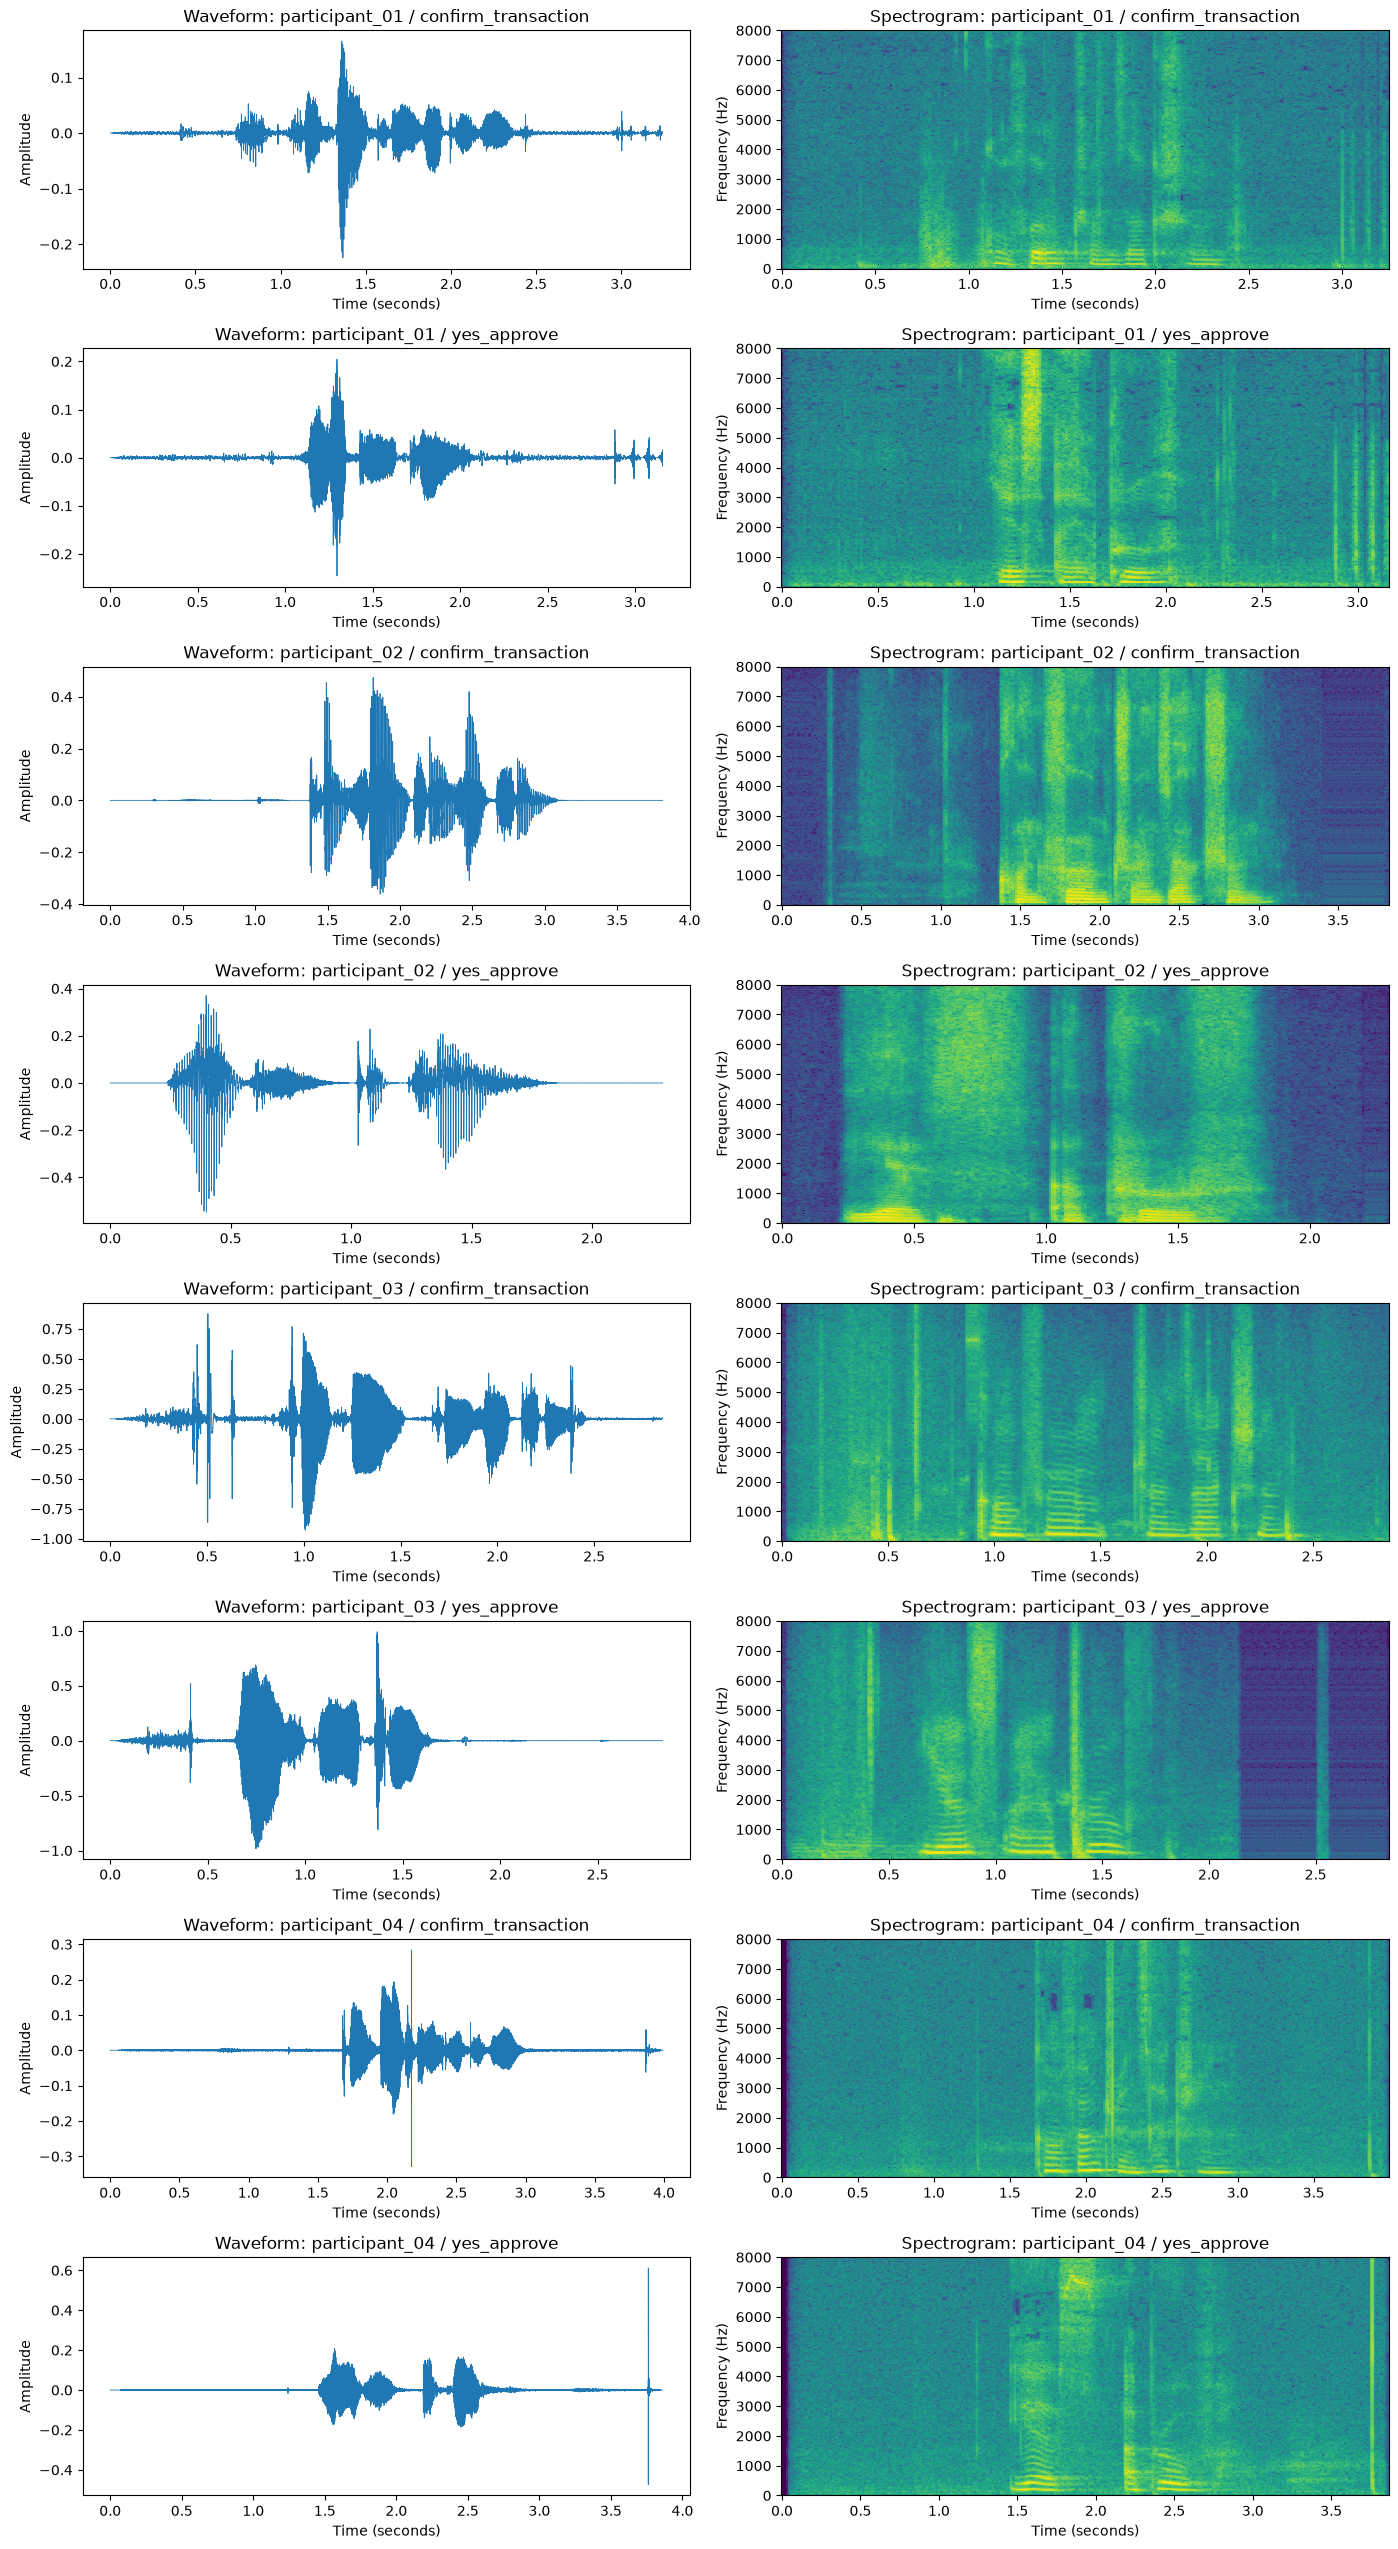

In [5]:
if not audio_records:
    raise ValueError("No usable recordings were loaded. Check the skipped-recording report.")

fig, axes = plt.subplots(len(audio_records), 2, figsize=(14, 3.2 * len(audio_records)))
axes = np.atleast_2d(axes)

for index, sample in enumerate(audio_records):
    signal, sr = sample["signal"], sample["sample_rate"]
    time_axis = np.arange(len(signal)) / sr
    axes[index, 0].plot(time_axis, signal, linewidth=0.6)
    axes[index, 0].set_title(
        f'Waveform: {sample["participant_id"]} / {sample["phrase"]}'
    )
    axes[index, 0].set_xlabel("Time (seconds)")
    axes[index, 0].set_ylabel("Amplitude")

    frequencies, times, spectrum = stft(
        signal, fs=sr, nperseg=512, noverlap=384
    )
    axes[index, 1].pcolormesh(
        times, frequencies, 20 * np.log10(np.abs(spectrum) + 1e-8),
        shading="auto"
    )
    axes[index, 1].set_ylim(0, 8000)
    axes[index, 1].set_title(
        f'Spectrogram: {sample["participant_id"]} / {sample["phrase"]}'
    )
    axes[index, 1].set_xlabel("Time (seconds)")
    axes[index, 1].set_ylabel("Frequency (Hz)")

    peak = float(np.max(np.abs(signal)))
    rms = float(np.sqrt(np.mean(signal ** 2)))
    print(
        f'{sample["participant_id"]} / {sample["phrase"]}: '
        f'{sample["duration_seconds"]:.2f}s, peak amplitude={peak:.3f}, '
        f'RMS={rms:.4f}. Interpretation: the waveform shows speech timing '
        'and amplitude; the spectrogram shows how frequency energy changes '
        'through the phrase. Very low amplitude may indicate a quiet sample, '
        'while flat regions may indicate pauses.'
    )

plt.tight_layout()
plt.show()

## 5.1 Waveforms and spectrograms for every recording

A waveform and spectrogram are plotted for each original recording, rather than selecting only the first file. The printed notes report duration and amplitude and explain what each visualisation reveals. Waveforms help identify pauses and amplitude variation, while spectrograms show the distribution of frequency energy over time.

## 6. Apply audio augmentation

Additional versions of each recording are created using small pitch changes, time stretching and low-level background noise. The changes are kept fairly small so that the recordings still resemble the original speech.

These versions are useful for training, but they are not new independent voice samples. All augmented versions from one original recording should stay together when the data is split into training and testing groups.

In [6]:
def pitch_shift(signal, semitones):
    factor = 2 ** (semitones / 12)
    intermediate = max(16, int(len(signal) / factor))
    shifted = np.interp(
        np.linspace(0, len(signal) - 1, intermediate),
        np.arange(len(signal)), signal
    )
    restored = np.interp(
        np.linspace(0, len(shifted) - 1, len(signal)),
        np.arange(len(shifted)), shifted
    )
    return restored.astype(np.float32)

def time_stretch(signal, rate, n_fft=1024, hop=256):
    if rate <= 0:
        raise ValueError("rate must be positive")
    _, _, z = stft(signal, fs=TARGET_SR, nperseg=n_fft,
                   noverlap=n_fft-hop, boundary="zeros", padded=True)
    steps = np.arange(0, z.shape[1] - 1, rate)
    phase_advance = 2 * np.pi * hop * np.arange(n_fft // 2 + 1) / n_fft
    output = np.zeros((z.shape[0], len(steps)), dtype=np.complex128)
    phase = np.angle(z[:, 0])
    for i, step in enumerate(steps):
        left = int(step)
        frac = step - left
        magnitude = (1 - frac) * np.abs(z[:, left]) + frac * np.abs(z[:, left + 1])
        delta = np.angle(z[:, left + 1]) - np.angle(z[:, left]) - phase_advance
        delta = (delta + np.pi) % (2 * np.pi) - np.pi
        phase += phase_advance + delta
        output[:, i] = magnitude * np.exp(1j * phase)
    _, stretched = istft(output, fs=TARGET_SR, nperseg=n_fft,
                         noverlap=n_fft-hop, input_onesided=True,
                         boundary=True)
    target_len = max(1, int(len(signal) / rate))
    if len(stretched) < target_len:
        stretched = np.pad(stretched, (0, target_len - len(stretched)))
    return stretched[:target_len].astype(np.float32)

def add_noise(signal, snr_db=25, seed=42):
    rng = np.random.default_rng(seed)
    signal_power = np.mean(signal ** 2) + 1e-12
    noise_power = signal_power / (10 ** (snr_db / 10))
    noisy = signal + rng.normal(0, np.sqrt(noise_power), len(signal))
    return np.clip(noisy, -1, 1).astype(np.float32)

augmented_records = []
for idx, item in enumerate(tqdm(audio_records)):
    base = item["signal"]
    variants = [
        ("original", base),
        ("pitch_up_2", pitch_shift(base, 2)),
        ("pitch_down_2", pitch_shift(base, -2)),
        ("time_stretch_0_9", time_stretch(base, 0.9)),
        ("time_stretch_1_1", time_stretch(base, 1.1)),
        ("noise_25db", add_noise(base, 25, seed=idx))
    ]
    for aug_name, audio in variants:
        filename = f"{item['participant_id']}_{idx:04d}_{item['phrase']}_{aug_name}.wav"
        out_path = AUGMENTED_DIR / filename
        wavfile.write(str(out_path), TARGET_SR, audio)
        augmented_records.append({
            "audio_path": str(out_path),
            "source_path": item["source_path"],
            "participant_id": item["participant_id"],
            "phrase": item["phrase"],
            "augmentation": aug_name,
            "signal": audio
        })

print("Original recordings:", len(audio_records))
print("Augmented recordings including originals:", len(augmented_records))

  0%|          | 0/8 [00:00<?, ?it/s]

Original recordings: 8
Augmented recordings including originals: 48


## 7. Extract audio features

Thirteen MFCC coefficients are extracted, and their mean and standard deviation are calculated across the audio frames. Summary values are also calculated for 85% spectral roll-off and RMS energy. These features provide the classifiers with a compact description of the recordings, although they are simpler than modern speaker embeddings.

In [7]:
def mel_to_hz(mel):
    return 700 * (10 ** (mel / 2595) - 1)

def hz_to_mel(hz):
    return 2595 * np.log10(1 + hz / 700)

def mel_filterbank(sr, n_fft=512, n_mels=26):
    low_mel, high_mel = hz_to_mel(0), hz_to_mel(sr / 2)
    mel_points = np.linspace(low_mel, high_mel, n_mels + 2)
    hz_points = mel_to_hz(mel_points)
    bins = np.floor((n_fft + 1) * hz_points / sr).astype(int)
    filters = np.zeros((n_mels, n_fft // 2 + 1))
    for m in range(1, n_mels + 1):
        left, center, right = bins[m-1:m+2]
        center = max(center, left + 1)
        right = max(right, center + 1)
        for k in range(left, min(center, filters.shape[1])):
            filters[m-1, k] = (k-left) / (center-left)
        for k in range(center, min(right, filters.shape[1])):
            filters[m-1, k] = (right-k) / (right-center)
    return filters

MEL_FILTERS = mel_filterbank(TARGET_SR)

def extract_audio_features(signal, sr=TARGET_SR):
    _, _, z = stft(signal, fs=sr, nperseg=512, noverlap=352,
                   boundary=None, padded=False)
    power = np.abs(z) ** 2
    mel_power = MEL_FILTERS @ power
    log_mel = np.log(mel_power + 1e-10)
    mfcc = dct(log_mel, type=2, axis=0, norm="ortho")[:13]

    freqs = np.linspace(0, sr / 2, power.shape[0])
    cumulative = np.cumsum(power, axis=0)
    totals = cumulative[-1, :] + 1e-12
    rolloff_idx = np.argmax(cumulative >= 0.85 * totals[None, :], axis=0)
    rolloff = freqs[rolloff_idx]
    frame_energy = np.sqrt(np.mean(np.abs(z) ** 2, axis=0))

    features = {}
    for i in range(13):
        features[f"mfcc_{i+1:02d}_mean"] = float(np.mean(mfcc[i]))
        features[f"mfcc_{i+1:02d}_std"] = float(np.std(mfcc[i]))
    features["spectral_rolloff_mean"] = float(np.mean(rolloff))
    features["spectral_rolloff_std"] = float(np.std(rolloff))
    features["rms_energy_mean"] = float(np.mean(frame_energy))
    features["rms_energy_std"] = float(np.std(frame_energy))
    features["duration_seconds"] = float(len(signal) / sr)
    return features

feature_rows = []
for item in tqdm(augmented_records):
    row = {
        "audio_path": item["audio_path"],
        "source_path": item["source_path"],
        "participant_id": item["participant_id"],
        "phrase": item["phrase"],
        "augmentation": item["augmentation"]
    }
    row.update(extract_audio_features(item["signal"]))
    feature_rows.append(row)

audio_features = pd.DataFrame(feature_rows)
print("Audio feature table shape:", audio_features.shape)
display(audio_features.head())

  0%|          | 0/48 [00:00<?, ?it/s]

Audio feature table shape: (48, 36)


,audio_path,source_path,participant_id,phrase,augmentation,mfcc_01_mean,mfcc_01_std,mfcc_02_mean,mfcc_02_std,mfcc_03_mean,...,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,spectral_rolloff_mean,spectral_rolloff_std,rms_energy_mean,rms_energy_std,duration_seconds
0,c:\Users\a\Documents\formative_2_data_processi...,c:\Users\a\Documents\formative_2_data_processi...,participant_01,confirm_transaction,original,-84.129809,8.888358,6.474844,4.643184,2.762769,...,0.956708,-0.586556,0.862987,-0.700591,0.947292,1174.883540,1407.258433,0.000513,0.000716,3.242688
1,c:\Users\a\Documents\formative_2_data_processi...,c:\Users\a\Documents\formative_2_data_processi...,participant_01,confirm_transaction,pitch_up_2,-86.297314,8.979724,8.803772,4.588557,1.639175,...,0.906436,-0.540168,0.862333,-0.751894,1.008618,780.376553,891.915079,0.000502,0.000713,3.242688
2,c:\Users\a\Documents\formative_2_data_processi...,c:\Users\a\Documents\formative_2_data_processi...,participant_01,confirm_transaction,pitch_down_2,-85.878115,8.918641,8.367285,4.637727,1.831043,...,0.929836,-0.544948,0.851948,-0.747551,0.981999,825.310559,980.069809,0.000504,0.000714,3.242688
3,c:\Users\a\Documents\formative_2_data_processi...,c:\Users\a\Documents\formative_2_data_processi...,participant_01,confirm_transaction,time_stretch_0_9,-87.191944,8.713080,6.383327,4.473832,2.528749,...,0.903226,-0.680293,0.876073,-0.748385,0.986638,1287.884078,1537.704681,0.000348,0.000469,3.602937
4,c:\Users\a\Documents\formative_2_data_processi...,c:\Users\a\Documents\formative_2_data_processi...,participant_01,confirm_transaction,time_stretch_1_1,-87.002240,8.507241,6.475781,4.482570,2.546684,...,1.020424,-0.637144,0.870118,-0.777487,0.921059,1256.207192,1475.198609,0.000365,0.000491,2.947875


## 8. Save the outputs and check the results

The main output is `audio_features.csv`. An inventory of the recordings and a list of files that could not be processed are also saved. These files are checked so that the feature table can be traced back to the original recordings.

In [8]:
features_path = PROCESSED_DIR / "audio_features.csv"
inventory_path = PROCESSED_DIR / "audio_inventory.csv"
skipped_path = PROCESSED_DIR / "skipped_audio.csv"

audio_features.to_csv(features_path, index=False)
inventory.drop(columns=["path"]).assign(
    path=inventory["path"].astype(str)
).to_csv(inventory_path, index=False)
pd.DataFrame(skipped, columns=["file", "reason"]).to_csv(skipped_path, index=False)

print("Saved:")
print(features_path)
print(inventory_path)
print(skipped_path)

print("\nOriginal recordings represented by participant:")
print(pd.DataFrame(audio_records).groupby("participant_id").size())
print("\nFeature rows by augmentation:")
display(audio_features["augmentation"].value_counts().to_frame("rows"))

Saved:
c:\Users\a\Documents\formative_2_data_processing_personal\data\audio\processed\audio_features.csv
c:\Users\a\Documents\formative_2_data_processing_personal\data\audio\processed\audio_inventory.csv
c:\Users\a\Documents\formative_2_data_processing_personal\data\audio\processed\skipped_audio.csv

Original recordings represented by participant:
participant_id
participant_01    2
participant_02    2
participant_03    2
participant_04    2
dtype: int64

Feature rows by augmentation:


,rows
augmentation,
original,8
pitch_up_2,8
pitch_down_2,8
time_stretch_0_9,8
time_stretch_1_1,8
noise_25db,8


## 9. Interpretation and limitations

The original recording inventory is checked to confirm that all four participants and both phrases are represented. The plots are reviewed and the recordings are listened to for silence, clipping and inconsistent recording conditions.

The dataset is small, and creating augmented versions does not replace collecting more genuine recordings. The features extracted here are baseline features for the voice model, not a complete speaker-verification system. The next notebook uses the image, audio and customer features to train and evaluate the models.